# Notebook 08: Divisible vs. Markovian: two tests on two different objects

**Goal:** Put Barandes's divisibility (a property of the transition matrices $\Gamma$) side by side with the
textbook meaning of "Markovian" for open quantum systems (CP-divisibility of the quantum channel,
Nielsen & Chuang ch. 8), and map where the two agree and where they do not.

By the end of this notebook you will be able to:
- State both tests and run them on the same qubit
- Show that a closed qubit is Markovian by the textbook test and indivisible by Barandes's, with the largest possible revival
- Locate the exact boundary for steady dephasing: $\Gamma$ becomes divisible at critical damping, $\Gamma_\varphi = 2\omega$
- Connect notebook 06's records to the textbook's phase damping channel, and trace the boundary between them
- Find all four combinations (both, neither, one but not the other) in one family of models

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from isp.stochastic import PairwiseProcess
from isp.divisibility import check_divisibility_lp

## 1. Two Tests on the Same Qubit

System: a qubit with configurations 0 and 1 and $H = \frac{\omega}{2}\sigma_x$, as in notebooks 03 and 06. Time is in units of $1/\omega$.
Noise: dephasing in the configuration basis (Nielsen & Chuang §8.3.6, §8.4.1), with Lindblad operator $\sigma_z$ and
rate $\Gamma_\varphi(t)$, normalized so that with no Hamiltonian the coherence decays as $e^{-\Gamma_\varphi t}$:

$$\dot\rho = -i[H,\rho] + \frac{\Gamma_\varphi(t)}{2}\,\big(\sigma_z\rho\,\sigma_z - \rho\big).$$

Write $\mathcal{E}(t \leftarrow t')$ for the quantum channel (a superoperator) that carries $\rho(t')$ to $\rho(t)$.

**Barandes's test (divisibility of $\Gamma$).** $\Gamma_{ij}(t \leftarrow 0) = \langle i|\,\mathcal{E}(t \leftarrow 0)\big(|j\rangle\langle j|\big)\,|i\rangle$.
The process is divisible at $t'$ if *some* valid stochastic matrix $\Gamma(t \leftarrow t')$ satisfies
$\Gamma(t \leftarrow 0) = \Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow 0)$ for every later $t$.
Every model here is symmetric under swapping 0 and 1, so $\Gamma = \frac12\begin{pmatrix}1+\lambda & 1-\lambda\\ 1-\lambda & 1+\lambda\end{pmatrix}$ and notebook 06's
gap rule applies (Pimenta, arXiv:2505.08785, §IV, applies the Buscemi–Datta criterion to 2×2 Γ in this way): the pair $(t', t)$ divides exactly when $|\lambda(t)| \le |\lambda(t')|$. The single number

$$R = \max_{t' < t}\big(|\lambda(t)| - |\lambda(t')|\big)_+$$

is 0 exactly when $\Gamma$ is divisible over every pair of times. $|\lambda|$ is the Kolmogorov (total-variation) distance
between the two columns. Smirne, Stabile and Vacchini (2013) use this distance as a classical non-Markovianity witness;
$R$ is zero exactly when their measure is, but it takes the largest single revival rather than their integral over all increases.

**The textbook test (CP-divisibility of the channel).** The dynamics is Markovian in the open-systems sense
when every intermediate map $\mathcal{E}(t \leftarrow t')$ is itself a valid quantum operation, i.e. completely positive.
Complete positivity is checked with the Choi matrix $C = \sum_{ij} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$: it must have no negative
eigenvalue. The intermediate maps are computed by propagating from $t'$ to $t$ directly, never by inverting.

In [2]:
OMEGA = 1.0
SX = np.array([[0, 1], [1, 0]], complex)
SZ = np.diag([1.0, -1.0]).astype(complex)
I2 = np.eye(2)
H = OMEGA / 2 * SX


def lindbladian(rate):
    # Superoperator (column-stacking vec) for H plus sigma_z dephasing at the given rate.
    L = -1j * (np.kron(I2, H) - np.kron(H.T, I2))
    return L + rate / 2 * (np.kron(SZ.conj(), SZ) - np.kron(I2, I2))


def channel_steps(rate_fn, ts, nsub=8):
    # One-step channels E(t[a+1] <- t[a]) for a time-dependent rate, by short-time products.
    steps = []
    for a in range(len(ts) - 1):
        h = (ts[a + 1] - ts[a]) / nsub
        S = np.eye(4, dtype=complex)
        for k in range(nsub):
            S = expm(lindbladian(rate_fn(ts[a] + (k + 0.5) * h)) * h) @ S
        steps.append(S)
    return steps


def from_zero(steps):
    E, out = np.eye(4, dtype=complex), [np.eye(4, dtype=complex)]
    for S in steps:
        E = S @ E
        out.append(E)
    return out


def apply(E, rho):
    return (E @ rho.reshape(-1, order='F')).reshape(2, 2, order='F')


def gamma_of(E):
    # Gamma_ij = <i| E(|j><j|) |i>
    G = np.zeros((2, 2))
    for j in range(2):
        r = np.zeros((2, 2), complex); r[j, j] = 1
        G[:, j] = np.real(np.diag(apply(E, r)))
    return G


def choi_min(E):
    C = np.zeros((4, 4), complex)
    for i in range(2):
        for j in range(2):
            r = np.zeros((2, 2), complex); r[i, j] = 1
            C += np.kron(r, apply(E, r))
    return np.linalg.eigvalsh((C + C.conj().T) / 2).min()


def cp_defect(steps, stride=4):
    # Largest negative Choi eigenvalue over intermediate maps E(t <- t'); 0 means CP-divisible.
    worst, n = 0.0, len(steps) + 1
    for a in range(0, n, stride):
        M = np.eye(4, dtype=complex)
        for b in range(a + 1, n):
            M = steps[b - 1] @ M
            worst = min(worst, choi_min(M))
    return max(0.0, -worst)


def stretch(Gs):
    lam = np.array([G[0, 0] - G[0, 1] for G in Gs])
    assert np.allclose([G[1, 1] - G[1, 0] for G in Gs], lam), 'family is not 0<->1 symmetric'
    return lam


def revival(lam):
    # R = max over t' < t of (|lam(t)| - |lam(t')|)_+ ; 0 means Gamma divisible over every pair
    L = np.abs(lam)
    return max(0.0, float(np.max(L[1:] - np.minimum.accumulate(L)[:-1])))


def divides_lp(G_tp, G_t):
    # Inverse-free check from notebook 05: does ANY valid Gamma(t <- t') exist?
    proc = PairwiseProcess(states=['0', '1'], times=[0.0, 1.0, 2.0], matrices={(0, 1): G_tp, (0, 2): G_t})
    return check_divisibility_lp(proc)['divisible']

In [3]:
ts = np.linspace(0, 12, 121)
for rate in (0.0, 1.0, 3.0):
    steps = channel_steps(lambda t: rate, ts, nsub=1)
    Gs = [gamma_of(E) for E in from_zero(steps)]
    lam = stretch(Gs)
    rng = np.random.default_rng(int(10 * rate))
    agree = 0
    for _ in range(40):
        a, b = sorted(rng.choice(np.arange(1, len(ts)), 2, replace=False))
        agree += divides_lp(Gs[a], Gs[b]) == (abs(lam[b]) <= abs(lam[a]) + 1e-12)
    print(f'Γφ/ω = {rate}:  CP defect = {cp_defect(steps):.1e}   Γ revival R = {revival(lam):.3f}   '
          f'gap rule agrees with LP test on {agree}/40 random pairs')

Γφ/ω = 0.0:  CP defect = 7.7e-16   Γ revival R = 0.987   gap rule agrees with LP test on 40/40 random pairs
Γφ/ω = 1.0:  CP defect = 0.0e+00   Γ revival R = 0.157   gap rule agrees with LP test on 40/40 random pairs
Γφ/ω = 3.0:  CP defect = 0.0e+00   Γ revival R = 0.000   gap rule agrees with LP test on 40/40 random pairs


## 2. Steady Dephasing: The Two Tests Part Ways Below Critical Damping

With a constant rate the generator is time-independent and of Lindblad form with a positive rate, so every
intermediate map is a valid channel: the dynamics is CP-divisible (Markovian in the textbook sense) for
**every** $\Gamma_\varphi \ge 0$, including $\Gamma_\varphi = 0$, the closed qubit.

The populations tell a different story. With $\lambda = \rho_{00} - \rho_{11}$ and coherence $y$, the Bloch equations are
$\dot y = -\Gamma_\varphi y - \omega\lambda$ and $\dot\lambda = \omega y$, so

$$\ddot\lambda + \Gamma_\varphi\,\dot\lambda + \omega^2\lambda = 0, \qquad \lambda(0) = 1,\ \dot\lambda(0) = 0,$$

a damped oscillator. Below critical damping ($\Gamma_\varphi < 2\omega$) $\lambda$ swings through zero and $|\lambda|$ revives: $\Gamma$ is
indivisible. At and above it ($\Gamma_\varphi \ge 2\omega$) $\lambda$ decreases monotonically to 0: $\Gamma$ is divisible over every pair of times.

**Prior work.** That CP-divisibility and divisibility of the populations in a fixed basis are different conditions is
known: Vacchini, Smirne, Laine, Piilo and Breuer (2011). Benatti, Chruściński and Nichele (2024, arXiv:2405.05794) study
the "classical reduction" of a quantum dynamics to a fixed basis (Barandes's $\Gamma$ in our notation; they do not cite Barandes).
They show it can lose divisibility even when the quantum dynamics is P-divisible; their Example 2 is unitary dynamics.
They also note (§V), qualitatively, that with a Hamiltonian present large enough dissipative rates can keep the classical
reduction divisible. The explicit $\Gamma_\varphi = 2\omega$ threshold for this model was not found in our searches (2026-10-29,
2026-11-05); it is elementary (critical damping, the familiar crossover from damped Rabi oscillation to incoherent relaxation).

largest CP defect over the sweep: 6.0e-16   (CP-divisible at every rate)
Γφ/ω = 1.80:  Γ revival R = 1.43e-03
Γφ/ω = 1.90:  Γ revival R = 6.95e-05
Γφ/ω = 1.95:  Γ revival R = 9.77e-07
Γφ/ω = 1.99:  Γ revival R = 0.00e+00
Γφ/ω = 2.00:  Γ revival R = 0.00e+00
Γφ/ω = 2.05:  Γ revival R = 0.00e+00
Γφ/ω = 2.50:  Γ revival R = 0.00e+00


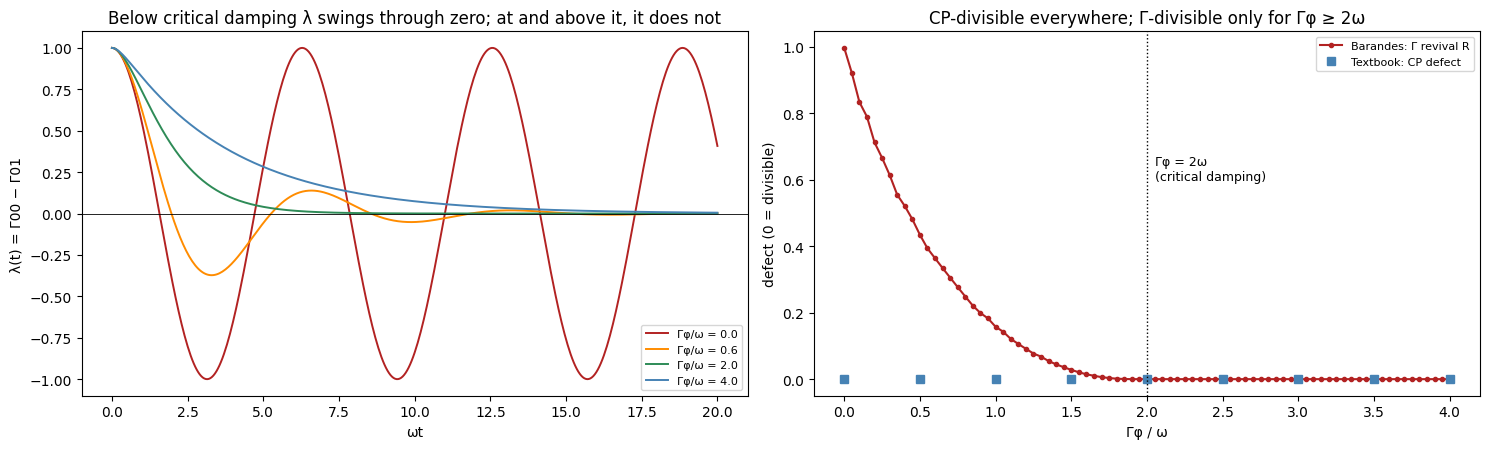

In [4]:
ts = np.linspace(0, 20, 401)
dtau = ts[1] - ts[0]


def constant_run(rate):
    step = expm(lindbladian(rate) * dtau)
    Gs = [gamma_of(E) for E in from_zero([step] * (len(ts) - 1))]
    return stretch(Gs)


rates = np.linspace(0, 4, 81)
R = [revival(constant_run(r)) for r in rates]
cp = [cp_defect([expm(lindbladian(r) * dtau)] * 40, stride=8) for r in rates[::10]]
print(f'largest CP defect over the sweep: {max(cp):.1e}   (CP-divisible at every rate)')
for r in (1.8, 1.9, 1.95, 1.99, 2.0, 2.05, 2.5):
    print(f'Γφ/ω = {r:4.2f}:  Γ revival R = {revival(constant_run(r)):.2e}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for r, color in [(0.0, 'firebrick'), (0.6, 'darkorange'), (2.0, 'seagreen'), (4.0, 'steelblue')]:
    axes[0].plot(ts, constant_run(r), color=color, lw=1.4, label=f'Γφ/ω = {r}')
axes[0].axhline(0, color='black', lw=0.6)
axes[0].set_xlabel('ωt'); axes[0].set_ylabel('λ(t) = Γ00 − Γ01')
axes[0].set_title('Below critical damping λ swings through zero; at and above it, it does not')
axes[0].legend(fontsize=8)
axes[1].plot(rates, R, 'o-', ms=3, color='firebrick', label='Barandes: Γ revival R')
axes[1].plot(rates[::10], cp, 's', ms=6, color='steelblue', label='Textbook: CP defect')
axes[1].axvline(2, color='black', ls=':', lw=1)
axes[1].text(2.05, 0.6, 'Γφ = 2ω\n(critical damping)', fontsize=9)
axes[1].set_xlabel('Γφ / ω'); axes[1].set_ylabel('defect (0 = divisible)')
axes[1].set_title('CP-divisible everywhere; Γ-divisible only for Γφ ≥ 2ω')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Notebook 06's Records Are the Textbook's Phase Damping Channel

Nielsen & Chuang's phase damping channel (§8.3.6, eqs. 8.127–8.128) has operation elements
$E_0 = \mathrm{diag}(1, \sqrt{1-\lambda_{pd}})$ and $E_1 = \mathrm{diag}(0, \sqrt{\lambda_{pd}})$. It leaves the populations alone and multiplies the coherence by
$\sqrt{1-\lambda_{pd}}$. Notebook 06's imperfect record with overlap $c$ does exactly the same thing, so a record is a phase damping
channel with $c = \sqrt{1-\lambda_{pd}}$. This is a restatement: Nielsen & Chuang's Figure 8.15 circuit is the same record. Barandes, Hasan and Kagan
(arXiv:2512.18105, §3.2) call the perfect-record case ($c = 0$), a channel that removes all configuration-basis coherence at a
division time, a "division channel".

Records every $\delta t$, with free rotation in between, are a product of valid channels, so the dynamics is CP-divisible
for every $c$ and every $\delta t$. Barandes divisibility over every pair of times needs records that are both frequent enough and
strong enough. For each spacing, find the largest overlap $c^*(\omega\delta t)$ that still keeps $\Gamma$ divisible:

- perfect records ($c = 0$) work up to $\omega\delta t = \pi/2$, notebook 06's result;
- frequent weak records act like steady dephasing at rate $\Gamma_\varphi = -\ln c\,/\,\delta t$, so section 2 predicts $c^* \to e^{-2\omega\delta t}$ as $\delta t \to 0$.

**Closed form.** With $\varphi = \omega\delta t$, one record step (rotation, then record) acts on the Bloch components $(y, z)$ as
$M = \begin{pmatrix} c\cos\varphi & -c\sin\varphi\\ \sin\varphi & \cos\varphi\end{pmatrix}$, with $\det M = c$ and $\mathrm{tr}\,M = (1+c)\cos\varphi$.
Its eigenvalues are complex, so $(y, z)$ spirals and $\lambda$ swings through zero, exactly when $(1+c)^2\cos^2\varphi < 4c$, i.e. when
$c > (1-\sin\varphi)/(1+\sin\varphi)$. A direct bisection for $R = 0$ over 4000 record spacings (next cell) puts the
boundary at the same point, to four decimals at every spacing printed:

$$c^*(\omega\delta t) = \frac{1 - \sin\omega\delta t}{1 + \sin\omega\delta t} \qquad (0 < \omega\delta t \le \pi/2).$$

It is $0$ at $\pi/2$ and $\approx e^{-2\omega\delta t - (\omega\delta t)^3/3}$ for small spacings: always slightly below the continuum value $e^{-2\omega\delta t}$.

records with c = 0.6 every ωδt = 1: CP defect of all intermediate maps = 3.1e-16


ωδt = 0.050:  c* bisection = 0.9048   closed form (1−sin ωδt)/(1+sin ωδt) = 0.9048   continuum e^(-2ωδt) = 0.9048
ωδt = 0.200:  c* bisection = 0.6685   closed form (1−sin ωδt)/(1+sin ωδt) = 0.6685   continuum e^(-2ωδt) = 0.6703
ωδt = 0.500:  c* bisection = 0.3519   closed form (1−sin ωδt)/(1+sin ωδt) = 0.3519   continuum e^(-2ωδt) = 0.3679
ωδt = 1.000:  c* bisection = 0.0861   closed form (1−sin ωδt)/(1+sin ωδt) = 0.0861   continuum e^(-2ωδt) = 0.1353
ωδt = 1.500:  c* bisection = 0.0013   closed form (1−sin ωδt)/(1+sin ωδt) = 0.0013   continuum e^(-2ωδt) = 0.0498
ωδt = 1.571:  c* bisection = 0.0000   closed form (1−sin ωδt)/(1+sin ωδt) = 0.0000   continuum e^(-2ωδt) = 0.0432


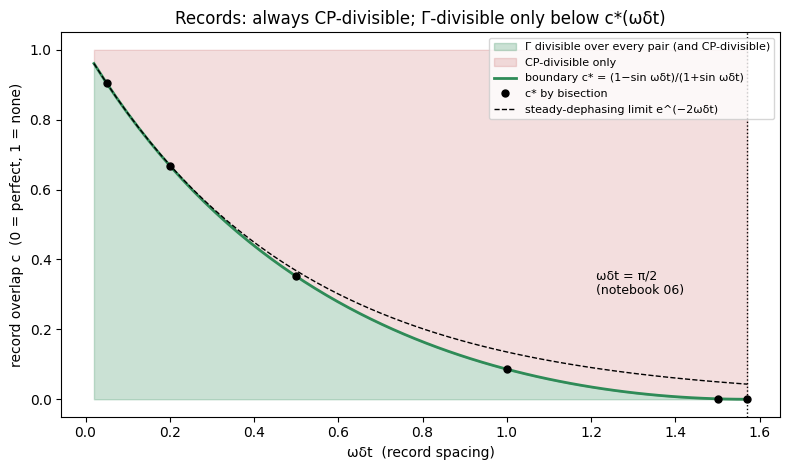

In [5]:
def lam_records(t, dt, c):
    # notebook 06 model: rotation about x between records, coherence multiplied by c at each record
    t = np.atleast_1d(t)
    k = np.floor(t / dt + 1e-9).astype(int)
    y, z, phi = [0.0], [1.0], OMEGA * dt
    for _ in range(k.max()):
        yy, zz = y[-1], z[-1]
        y.append(c * (yy * np.cos(phi) - zz * np.sin(phi)))
        z.append(yy * np.sin(phi) + zz * np.cos(phi))
    y0, z0, ph = np.array(y)[k], np.array(z)[k], OMEGA * (t - k * dt)
    return y0 * np.sin(ph) + z0 * np.cos(ph)


def c_star(wdt, n_records=4000, pts=100):
    # Bisect for the largest overlap c with R = 0. Near the boundary lambda first crosses zero very late,
    # so the window spans n_records record spacings and any revival at all counts (tolerance 0).
    grid = np.linspace(0, n_records * wdt, n_records * pts + 1)
    if revival(lam_records(grid, wdt, 0.0)) > 1e-12:
        return 0.0
    lo, hi = 0.0, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if revival(lam_records(grid, wdt, mid)) == 0 else (lo, mid)
    return lo


def c_star_exact(wdt):
    # where the eigenvalues of the one-record map on (y, z) turn complex; valid for 0 < wdt <= pi/2
    return (1 - np.sin(wdt)) / (1 + np.sin(wdt))


# CP check: record channel (Kraus form) and free rotation, intermediate maps across records
def superop_kraus(Ks):
    return sum(np.kron(K.conj(), K) for K in Ks)


def record_channel(c):
    lam_pd = 1 - c ** 2
    return superop_kraus([np.diag([1, np.sqrt(1 - lam_pd)]), np.diag([0, np.sqrt(lam_pd)])])


rot = expm(lindbladian(0.0) * 0.1)
steps = []
for m in range(60):                                      # dt = 1.0 split into 10 sub-steps, record at the end
    steps.append(record_channel(0.6) @ rot if m % 10 == 9 else rot)
print(f'records with c = 0.6 every ωδt = 1: CP defect of all intermediate maps = {cp_defect(steps, stride=3):.1e}')

wdts = np.linspace(0.02, np.pi / 2, 60)
cs = c_star_exact(wdts)
check_w = (0.05, 0.2, 0.5, 1.0, 1.5, np.pi / 2)
check_c = [c_star(w) for w in check_w]
for w, c_num in zip(check_w, check_c):
    print(f'ωδt = {w:.3f}:  c* bisection = {c_num:.4f}   closed form (1−sin ωδt)/(1+sin ωδt) = {c_star_exact(w):.4f}   '
          f'continuum e^(-2ωδt) = {np.exp(-2 * w):.4f}')

plt.figure(figsize=(8, 4.8))
plt.fill_between(wdts, 0, cs, color='seagreen', alpha=0.25, label='Γ divisible over every pair (and CP-divisible)')
plt.fill_between(wdts, cs, 1, color='firebrick', alpha=0.15, label='CP-divisible only')
plt.plot(wdts, cs, color='seagreen', lw=2, label='boundary c* = (1−sin ωδt)/(1+sin ωδt)')
plt.plot(check_w, check_c, 'o', color='black', ms=5, label='c* by bisection')
plt.plot(wdts, np.exp(-2 * wdts), 'k--', lw=1, label='steady-dephasing limit e^(−2ωδt)')
plt.axvline(np.pi / 2, color='black', ls=':', lw=1)
plt.text(np.pi / 2 - 0.36, 0.3, 'ωδt = π/2\n(notebook 06)', fontsize=9)
plt.xlabel('ωδt  (record spacing)'); plt.ylabel('record overlap c  (0 = perfect, 1 = none)')
plt.title('Records: always CP-divisible; Γ-divisible only below c*(ωδt)')
plt.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

## 4. A Time-Dependent Rate: All Four Combinations

Let the dephasing rate oscillate, $\Gamma_\varphi(t) = G_0\,\big(1 + k\cos 2\omega t\big)$. For $k > 1$ the rate is negative part of the time,
which is how non-Markovian dephasing is usually modelled. For a generator of this form, the intermediate maps are all
completely positive exactly when the rate never goes negative ($k \le 1$; the time-dependent GKSL criterion, Rivas, Huelga
and Plenio, Theorem 3.1; Hall, Cresser, Li and Andersson 2014). Some negative stretches are allowed physically, as
long as every map from time 0 stays a valid channel. Points where it does not are greyed out.

Each point of the $(G_0/\omega,\,k)$ plane gets one of four labels:
both divisible, CP-divisible only, $\Gamma$-divisible only, or neither.

That quantum and classical divisibility are different conditions is known in kind (Vacchini, Smirne, Laine, Piilo and
Breuer, 2011; Benatti, Chruściński and Nichele 2024, who compare quantum P-divisibility with divisibility of the classical
reduction). This map is one explicit family in which all four combinations occur.

both divisible     e.g. G0/ω = 2.27, k = 0.000
CP-divisible only  e.g. G0/ω = 0.25, k = 0.000
Γ-divisible only   e.g. G0/ω = 3.62, k = 1.062
neither            e.g. G0/ω = 0.25, k = 1.062


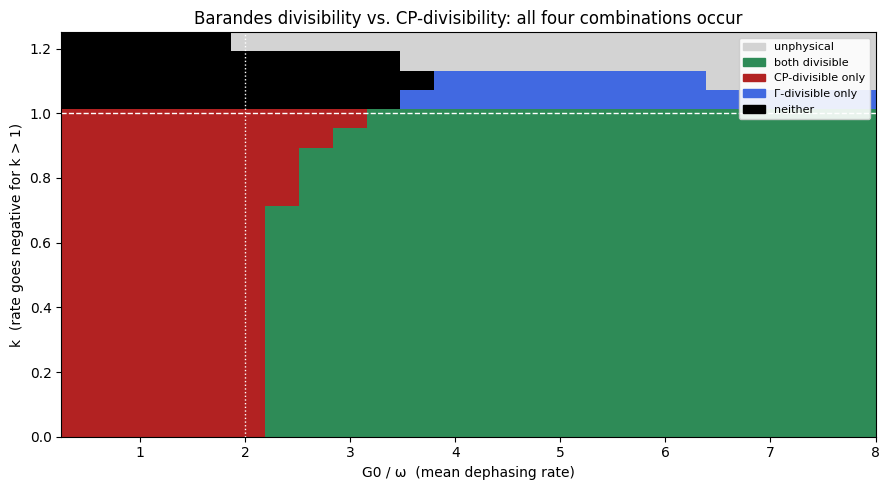

In [6]:
ts = np.linspace(0, 12, 121)
G0s = np.linspace(0.25, 8, 24)
ks = np.linspace(0, 1.25, 21)
label = np.zeros((len(ks), len(G0s)))
examples = {}
names = {0: 'unphysical', 1: 'both divisible', 2: 'CP-divisible only', 3: 'Γ-divisible only', 4: 'neither'}

for i, k in enumerate(ks):
    for j, G0 in enumerate(G0s):
        steps = channel_steps(lambda t: G0 * (1 + k * np.cos(2 * OMEGA * t)), ts, nsub=6)
        Ez = from_zero(steps)
        if min(choi_min(E) for E in Ez) < -1e-9:
            continue
        cp_ok = cp_defect(steps, stride=6) < 1e-9
        g_ok = revival(stretch([gamma_of(E) for E in Ez])) < 1e-9
        label[i, j] = {(True, True): 1, (True, False): 2, (False, True): 3, (False, False): 4}[(cp_ok, g_ok)]
        examples.setdefault(int(label[i, j]), (G0, k))

for code_, (G0, k) in sorted(examples.items()):
    print(f'{names[code_]:18s} e.g. G0/ω = {G0:.2f}, k = {k:.3f}')

from matplotlib.colors import ListedColormap
plt.figure(figsize=(9, 5))
plt.imshow(label, origin='lower', aspect='auto', extent=[G0s[0], G0s[-1], ks[0], ks[-1]],
           cmap=ListedColormap(['lightgrey', 'seagreen', 'firebrick', 'royalblue', 'black']), vmin=-0.5, vmax=4.5)
plt.axhline(1, color='white', ls='--', lw=1)
plt.axvline(2, color='white', ls=':', lw=1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c_) for c_ in ['lightgrey', 'seagreen', 'firebrick', 'royalblue', 'black']]
plt.legend(handles, [names[i] for i in range(5)], fontsize=8, loc='upper right', framealpha=0.9)
plt.xlabel('G0 / ω  (mean dephasing rate)'); plt.ylabel('k  (rate goes negative for k > 1)')
plt.title('Barandes divisibility vs. CP-divisibility: all four combinations occur')
plt.tight_layout()
plt.show()

## Summary

- Barandes's divisibility is a property of the transition matrices $\Gamma$, read in the configuration basis. The textbook's
  "Markovian" (CP-divisibility, Nielsen & Chuang ch. 8) is a property of the whole quantum channel. They are different conditions.
- A closed qubit is CP-divisible (every intermediate map is unitary) and indivisible in Barandes's sense, with the largest possible
  revival ($R = 1$ in continuous time; $0.987$ on this grid). Its Γ is the $\cos^2$ example of
  Barandes's Paper 1, eq. 7, and the general point is stated by Benatti, Chruściński and Nichele (2024): "for a unitary dynamics, P-divisibility
  of its classical reduction is inevitably lost".
- With steady dephasing, the dynamics is CP-divisible at every rate, while $\Gamma$ is divisible exactly when $\Gamma_\varphi \ge 2\omega$:
  the critical damping of $\ddot\lambda + \Gamma_\varphi\dot\lambda + \omega^2\lambda = 0$.
- Notebook 06's records are Nielsen & Chuang's phase damping channel with $c = \sqrt{1-\lambda_{pd}}$. They are always CP-divisible; $\Gamma$ is
  divisible below the boundary $c^*(\omega\delta t) = (1-\sin\omega\delta t)/(1+\sin\omega\delta t)$, which runs from notebook 06's $\omega\delta t = \pi/2$ (perfect records) to
  $e^{-2\omega\delta t}$ (frequent weak records, the critical-damping line), staying slightly below the latter.
- With an oscillating dephasing rate, all four combinations occur, including CP-indivisible but $\Gamma$-divisible dynamics
  (trivially so at $\omega = 0$, where the populations never move; the point is that it survives a non-zero $\omega$).

Below critical damping the revival has the closed form $R = \exp\!\big(-\pi\Gamma_\varphi/\sqrt{4\omega^2-\Gamma_\varphi^2}\big)$, which matches the printed sweep
(1.5e-3 predicted vs 1.43e-3 printed at $\Gamma_\varphi/\omega = 1.80$). At $1.99$ it is about $2.6\times10^{-14}$ and the first zero crossing comes at $\omega t \approx 30$,
after the window ends at $\omega t = 20$, so the sweep prints $R = 0$ there; the threshold itself is exactly $2\omega$.

Caveats: two configurations, symmetric dephasing in the configuration basis, and a finite time window and grid. Amplitude
damping (energy loss) breaks the 0↔1 symmetry and is not covered here.

**Prior work.** The concepts here are known. The comparison of CP-divisibility with classical divisibility of the
populations, and its failure in both directions, is in Vacchini, Smirne, Laine, Piilo and Breuer (2011), who already analysed
non-divisible classical transition-matrix families. Benatti, Chruściński and Nichele (2024, arXiv:2405.05794) study the
"classical reduction" of a quantum dynamics to a fixed basis (Barandes's $\Gamma$ in our notation; they do not cite Barandes) and
show it can lose divisibility even when the quantum dynamics is P-divisible; their Example 2 is unitary dynamics, and their §V
notes qualitatively that strong enough dissipation can restore classical divisibility. $\Gamma_\varphi = 2\omega$ is the explicit
threshold for this model. $R$ uses the Kolmogorov distance that Smirne, Stabile and Vacchini (2013) use as a non-Markovianity
witness; it is zero exactly when their measure is, but takes the largest single revival rather than their integral.
Records as phase damping is a restatement of Nielsen & Chuang §8.3.6; Barandes, Hasan and Kagan (arXiv:2512.18105 §3.2) call
the perfect-record case ($c = 0$) a "division channel".
Barandes himself draws the distinction: earlier forms of indivisibility in open-systems work "corresponded to quantum channels, not to stochastic processes" (Paper 3, §1, citing Wolf & Cirac 2008), and he credits Glick & Adami (Found. Phys. 50, 1008, 2020) with non-Markovianity in closed quantum systems and a Markovianity notion that "coincides with divisibility". Only the
$\Gamma_\varphi = 2\omega$ threshold was not found in our searches (2026-10-29 and 2026-11-05), and it is elementary.